**NAME:** ريتاج خالد الاشقر

**ID:** 446008786

## Introduction

In this lab session, we will work on the IMDB dataset

__The main objectives__ of today lab are the following:
- Learn how to train Feedforward Neural Network Model in Keras.
- Learn how to compile and test your model in Keras.
- learn how to visualize the Learning Curves.


##Loading the data and Preprocess it

In [ ]:
#Import numpy, pandas and tensorflow packages that we will use here.
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

# set seed for replicability of results
np.random.seed(1)
tf.random.set_seed(2)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Make sure you load the data with its correct shape (25000,)
train_data.shape


(25000,)

In [ ]:
train_labels.shape

(25000,)

In [ ]:
# To shuffle the entire DataFrame (both text and label together), we need to combine data and lebels
train_df = pd.DataFrame(train_data)
label_df = pd.DataFrame(train_labels, columns=["label"])

# Combine along columns (axis=1)
training_set = pd.concat([train_df, label_df], axis=1)
training_set.rename(columns={0: "text"}, inplace=True)

print(training_set.shape)  # (rows, columns+1)

(25000, 2)


In [ ]:
test_df = pd.DataFrame(test_data)
label_df = pd.DataFrame(test_labels, columns=["label"])

# Combine along columns (axis=1)
test_set = pd.concat([test_df, label_df], axis=1)
test_set.rename(columns={0: "text"}, inplace=True)

print(test_set.shape)  # (rows, columns+1)

(25000, 2)


In [ ]:
#Preprocess the data
from sklearn.utils import shuffle
from tensorflow.keras.preprocessing import text, sequence
from tensorflow.keras import utils

# Shuffle dataset
training_set = shuffle(training_set)

test_set = shuffle(test_set)

# Obtain text and label vectors
train_texts = training_set.text
train_labels = training_set.label


test_texts = test_set.text
test_labels = test_set.label

In [ ]:
#Encoding the integer sequences via multi-hot encoding
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))

    for i, sequence in enumerate(sequences):
      for j in sequence:
          results[i, j] = 1.
    return results
x_train = vectorize_sequences(train_texts)
x_test = vectorize_sequences(test_texts)

In [ ]:
x_train[0]

array([0., 1., 1., ..., 0., 0., 0.])

In [ ]:
# You Should also vectorize the labels
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

## Building the model architecture using Keras

This time, we will build a Sequential model with the following architecture:

- First Dense layer: 32 units, relu activation
- Second Dense layer: 32 units, relu activation
- Output Dense layer: 1 unit, sigmoid activation

__Then Compile the Model__ by specifying its configurations that control how it learns from the data. Specifically, we define the following:

- Optimizer: The optimizer controls how the model updates its weights during training. We'll use rmsprop

- Loss Function: The loss function measures how well the model's predictions match the actual labels. (Hint: Choose a loss function that suits our classification problem.)

- Metrics: Metrics help us track the model's performance. We'll use accuracy as a metric, which measures how often the model predicts the correct label.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Build the model
model = Sequential()

# First hidden layer
model.add(Dense(32, activation='relu', input_shape=(x_train.shape[1],)))

# Second hidden layer
model.add(Dense(32, activation='relu'))

# Output layer
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(
    optimizer='rmsprop',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │       320,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321,121 (1.22 MB)

 Trainable params: 321,121 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

##Train the Model
Now that the model is built, before we train it we need to create a validation set by setting aside the first 10,000 samples from the training data
Then train the model for 20 epochs with Batch size: 512


In [ ]:
#first we Create the validation set
x_val = x_train[:10000]
y_val = y_train[:10000]

partial_x_train = x_train[10000:]
partial_y_train = y_train[10000:]

In [ ]:
#the training set
history = model.fit(
    partial_x_train,
    partial_y_train,
    epochs=20,
    batch_size=512,
    validation_data=(x_val, y_val)
)

Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - accuracy: 0.7631 - loss: 0.5181 - val_accuracy: 0.8660 - val_loss: 0.3739
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.8929 - loss: 0.3027 - val_accuracy: 0.8508 - val_loss: 0.3549
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.9149 - loss: 0.2342 - val_accuracy: 0.8913 - val_loss: 0.2773
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - accuracy: 0.9320 - loss: 0.1909 - val_accuracy: 0.8901 - val_loss: 0.2800
Epoch 5/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.9453 - loss: 0.1566 - val_accuracy: 0.8876 - val_loss: 0.2900
Epoch 6/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9526 - loss: 0.1375 - val_accuracy: 0.8856 - val_loss: 0.3031
Epoch 7/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9645 - loss: 0.1130 - val_accuracy: 0.8835 - val_loss: 0.3202
Epoch 8/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9683 - loss: 0.0992 - val_accuracy: 0.8820 - 

## Question 1
Explain the key components of the first epoch result?

In the first epoch, the model completed 30 batches of training data. It achieved a training accuracy of 76.31% with a training loss of 0.5181. On the validation set, it achieved a validation accuracy of 86.60% with a validation loss of 0.3739. The epoch took about 3 seconds, with approximately 74 ms per step.


## Visualize the Training Curves
Plot the training and validation loss over epochs
Plot the training and validation accuracy over epochs.
check if there is overfitting.



In [ ]:
#import matplotlib.pyplot as plt
#history_dict = history.history
#loss_values = history_dict["loss"]
#val_loss_values = history_dict["val_loss"]
#epochs = range(1, len(loss_values) + 1)
#plt.plot(epochs, loss_values, "bo", label="Training loss")
#plt.plot(epochs, val_loss_values, "b", label="Validation loss")
#plt.title("Training and validation loss")
#plt.xlabel("Epochs")
#plt.ylabel("Loss")
#plt.legend()
#plt.show()

#plt.clf()
#acc = history_dict["accuracy"]
#val_acc = history_dict["val_accuracy"]
#plt.plot(epochs, acc, "bo", label="Training acc")
#plt.plot(epochs, val_acc, "b", label="Validation acc")
#plt.title("Training and validation accuracy")
#plt.xlabel("Epochs")
#plt.ylabel("Accuracy")
#plt.legend()
#plt.show()

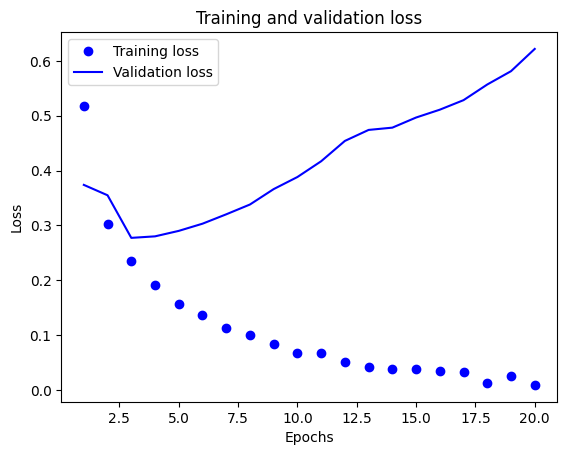

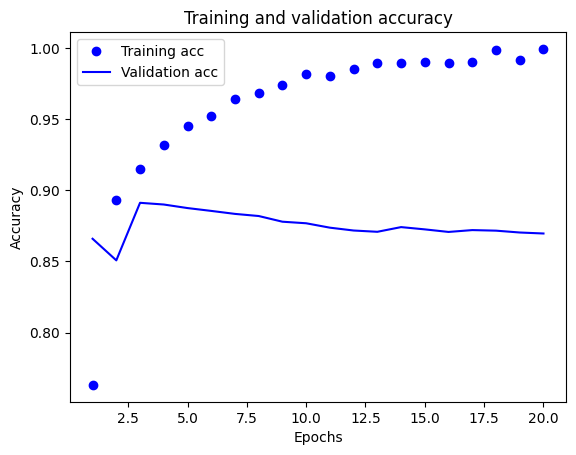

In [ ]:
import matplotlib.pyplot as plt

history_dict = history.history

loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

epochs = range(1, len(loss_values) + 1)

# Plot training and validation loss
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")

plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.show()


# Plot training and validation accuracy
plt.clf()

acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]

plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")

plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

##Question 2
At which epoch does the model start to overfit? Explain your reasoning based on the plots

The model starts to overfit around epoch 4. The validation loss reaches its minimum at epoch 3 and then begins to increase, while the training loss continues to decrease. At the same time, the training accuracy keeps increasing, but the validation accuracy stops improving and gradually decreases. This shows that the model is learning the training data too closely and is no longer improving on unseen validation data.

## Evaluate on the test set
Evaluate the performance of the model using test set

In [ ]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8592 - loss: 0.6407
Test Loss: 0.640714704990387
Test Accuracy: 0.8592000007629395


## Question 3

Now that you have a baseline model, systematically experiment with different architectures to understand how design choices affect performance.

1. Try using one or three representation layers, and see how doing so affects validation and test accuracy.
2. Try using layers with more units or fewer units: 16 units, 64 units, and so on.


 For each configuration, train the model and record:
   - best validation accuracy achieved
   - the epoch at which validation loss was lowest
   - test accuracy
   - approximate training time (use %%time or time.time())

 Fill in this table as you go:

 | Config          | Best Val Acc | Epoch of Best Val Loss | Test Acc | Time/epoch |
  |-----------------|--------------|--------------------------|----------|------------|
  1 layer 16u    
  2 layers, 16u               
  3 layers, 16u
  2 layers, 32u
  2 layers, 64u


- Based on your results table, does increasing the number of layers or units actually improve validation/test accuracy, or does it mainly increase training time and overfitting risk?

In [ ]:
#Q3 test
import time
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


def run_experiment(name, num_layers, units):

    # Build model
    model = Sequential()

    model.add(Dense(
        units,
        activation='relu',
        input_shape=(x_train.shape[1],)
    ))

    # Add remaining hidden layers
    for _ in range(num_layers - 1):
        model.add(Dense(units, activation='relu'))

    # Output layer
    model.add(Dense(1, activation='sigmoid'))

    # Compile
    model.compile(
        optimizer='rmsprop',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Measure training time
    start_time = time.time()

    history = model.fit(
        partial_x_train,
        partial_y_train,
        epochs=20,
        batch_size=512,
        validation_data=(x_val, y_val),
        verbose=0
    )

    end_time = time.time()

    total_time = end_time - start_time
    time_per_epoch = total_time / 20

    # Best validation accuracy
    best_val_acc = max(history.history['val_accuracy'])

    # Epoch where validation loss was lowest
    best_loss_epoch = np.argmin(
        history.history['val_loss']
    ) + 1

    # Test accuracy
    test_loss, test_acc = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    return {
        "Config": name,
        "Best Val Acc": best_val_acc,
        "Epoch of Best Val Loss": best_loss_epoch,
        "Test Acc": test_acc,
        "Time/epoch": time_per_epoch
    }


# Run all five experiments
results = []

results.append(
    run_experiment("1 layer 16u", 1, 16)
)

results.append(
    run_experiment("2 layers, 16u", 2, 16)
)

results.append(
    run_experiment("3 layers, 16u", 3, 16)
)

results.append(
    run_experiment("2 layers, 32u", 2, 32)
)

results.append(
    run_experiment("2 layers, 64u", 2, 64)
)


# Create results table In Q3
results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


       Config  Best Val Acc  Epoch of Best Val Loss  Test Acc  Time/epoch
  1 layer 16u        0.8908                       5   0.86408    1.582100
2 layers, 16u        0.8914                       4   0.85892    1.430303
3 layers, 16u        0.8895                       4   0.85716    1.382879
2 layers, 32u        0.8912                       4   0.85924    1.529227
2 layers, 64u        0.8910                       4   0.86264    2.684814


**AS FOR Q3**

Based on the results, increasing the number of layers or units did not significantly improve validation or test accuracy. The validation accuracies were very similar for all configurations, around 89%. The 1-layer 16-unit model achieved the highest test accuracy of 86.41%, while adding more layers did not improve the results. Increasing the number of units to 64 also did not significantly improve accuracy, but it increased the training time to about 2.68 seconds per epoch. Therefore, increasing model complexity mainly increased computational cost and may increase the risk of overfitting without providing a significant improvement in performance.

#Reference
- [Kersa Documentation](https://keras.io/getting_started/)
- [Tensorflow Documentation](https://www.tensorflow.org/learn)